In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv('../../data/processed/reg-szn/player_data_merged.csv')

In [17]:
# Grab PCA from EDA
scores = pd.read_csv('../../data/processed/reg-szn/pca_scores.csv')
pc_cols = [c for c in scores.columns if c.startswith('PC')]
X_pca = scores[pc_cols]

In [18]:
X_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,3.670733,0.082389,-0.395738,-0.280578,-1.740097,0.820665,1.342012
1,7.031763,2.394129,1.373684,-1.905985,-1.639699,-3.206950,-0.107169
2,-0.011131,2.232917,-2.311258,1.683359,-0.871462,0.547814,1.129884
3,1.634274,-3.997898,-0.397903,-1.235645,-0.209925,0.172383,0.070190
4,0.280834,0.099853,-1.484714,1.159856,-0.198962,-0.545351,0.495961
...,...,...,...,...,...,...,...
374,-0.406636,-2.336681,0.432336,2.127659,-0.930996,2.317523,-1.140433
375,-0.769863,-2.228162,-0.793294,-1.923219,0.240698,1.760034,-1.328132
376,0.779452,-0.280726,0.174685,-0.831370,2.903064,0.551547,0.069285
377,0.320727,-2.926944,-1.224661,-0.091917,1.207270,-0.279087,-0.211325


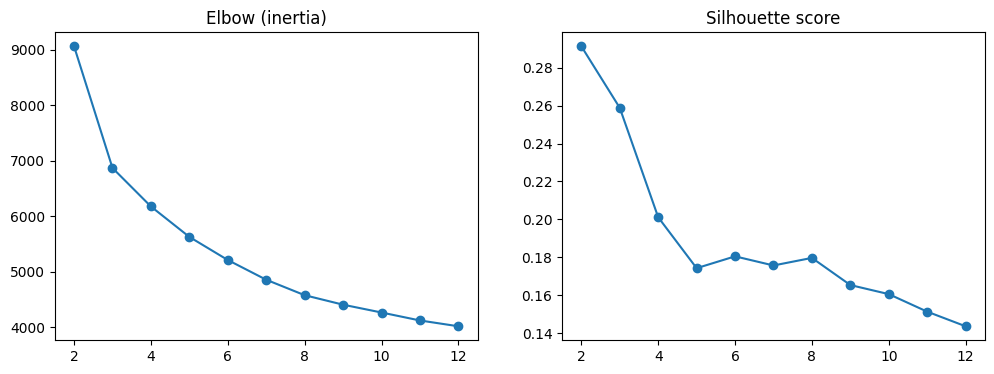

In [19]:
# Pick k: elbow + silhouette
ks = range(2, 13)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_pca)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_pca, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(ks, sils, marker='o');     ax[1].set_title('Silhouette score')
plt.show()


# k = 8 seems to be the most ideal.

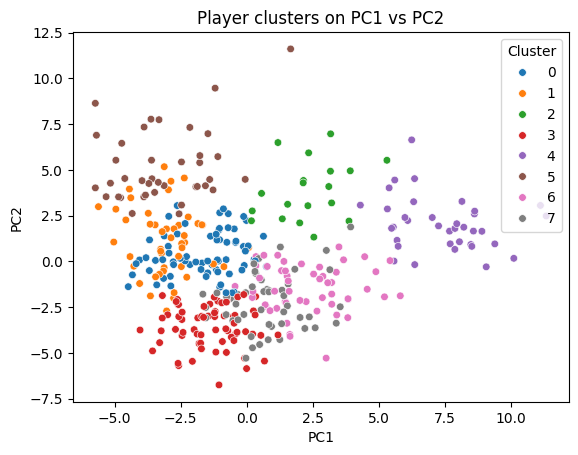

0 ['Bam Adebayo', 'Santi Aldama', 'Nickeil Alexander-Walker', 'Grayson Allen', 'Ace Bailey', 'Desmond Bane', 'RJ Barrett', 'Saddiq Bey']
1 ['Jose Alvarado', 'Cole Anthony', 'Lonzo Ball', 'Bub Carrington', 'Devin Carter', 'Walter Clayton', 'Isaiah Collier', 'Sharife Cooper']
2 ['Scottie Barnes', 'Anthony Davis', 'Kyle Filipowski', 'Chet Holmgren', 'Jaren Jackson Jr.', 'Evan Mobley', 'Jusuf Nurkić', 'Kristaps Porziņģis']
3 ['Harrison Barnes', 'Jamison Battle', 'Nicolas Batum', 'Mikal Bridges', 'Kobe Brown', 'Toumani Camara', 'Jevon Carter', 'Julian Champagnie']
4 ['Steven Adams', 'Jarrett Allen', 'Deandre Ayton', 'Marvin Bagley III', 'Goga Bitadze', 'Adem Bona', 'Clint Capela', 'Dylan Cardwell']
5 ['Giannis Antetokounmpo', 'Deni Avdija', 'LaMelo Ball', 'Paolo Banchero', 'Devin Booker', 'Jaylen Brown', 'Jalen Brunson', 'Jimmy Butler']
6 ['Precious Achiuwa', 'Ochai Agbaji', 'Dominick Barlow', 'Christian Braun', 'Carter Bryant', 'Thomas Bryant', 'Matas Buzelis', 'Wendell Carter Jr.']
7 ['Ky

In [20]:
k = 8 
km = KMeans(n_clusters=k, n_init=20, random_state=42)
scores['Cluster'] = km.fit_predict(X_pca)

sns.scatterplot(data=scores, x='PC1', y='PC2', hue='Cluster', palette='tab10', s=30)
plt.title('Player clusters on PC1 vs PC2')
plt.show()

for c, grp in scores.groupby('Cluster'):
    print(c, grp['Player'].head(8).tolist())


In [22]:
# cluster 0: I have no idea what this category is- it could be lock & playmakers?
# cluster 1: Looks like lock guards of sorts, not sure who most of these names are 
# cluster 2: Big men that can shoot and defend? Didn't know Jaren Jackson Jr shot alot of 3s
# cluster 3: 3 & d guards
# cluster 4: rim r unning big men
# cluster 5: ball handlers/play creators
# cluster 6: role players of sorts?
# cluster 7: This looks like primary defenders.